# Notebook 1 · Monday: reinforcement learning & Bayesian optimization
**MIME 525 · Simulation-Based Optimization and Reinforcement Learning**

This notebook follows Monday's slides **in order**. Each section is headed with its slide number and reproduces the numbers, tables or charts on that slide.
Every slide with code has a small line at the bottom: *"Code: Notebook 1 · section 'Slide N'"*.

Run the cells from top to bottom (Shift + Enter). Nothing to install: numpy, scipy, scikit-learn and matplotlib are already on Google Colab.

In [1]:
import warnings
warnings.filterwarnings("ignore")      # hide technical warnings so the output stays readable

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

---
## Slide 10 · Bandits: choosing a grind setpoint
Each shift the mill runs one of **3 grind setpoints** (coarse, medium, fine) and we see that shift's profit.
Ore changes shift to shift, so profit is noisy (σ = $25k). The true average profits are hidden from the agent.

The agent keeps two numbers per setpoint:
* `tries[a]`: how many shifts setpoint `a` has run
* `estimate[a]`: its running average profit, updated with **Q(a) ← Q(a) + (r − Q(a)) / N(a)**

`run_mill` plays 500 shifts with one of the five methods on the slide.

In [2]:
true_profit = [100, 115, 108]   # $k per shift: coarse, medium, fine. HIDDEN from the agent
noise = 25                      # shift-to-shift variation ($k)

def run_mill(method, shifts=500, seed=0, epsilon=0.1, c=30, alpha=0.02, eps0=0.5, decay=0.99, eps_min=0.01):
    rng = np.random.default_rng(seed)
    estimate = np.zeros(3)          # Q(a): running average profit of each setpoint
    tries = np.zeros(3)             # N(a): shifts run on each setpoint
    preference = np.zeros(3)        # H(a): only used by the gradient method
    average = 0.0                   # average profit so far: only used by the gradient method
    profits = []

    for shift in range(shifts):
        # ---------- choose a setpoint ----------
        if method == "gradient":                          # probabilities from preferences (softmax)
            prob = np.exp(preference) / np.exp(preference).sum()
            choice = rng.choice(3, p=prob)
        elif shift < 3:
            choice = shift                                # first, try each setpoint once
        elif method == "greedy":
            choice = int(np.argmax(estimate))             # always the best so far
        elif method == "epsilon":
            if rng.random() < epsilon:
                choice = rng.integers(3)                  # explore
            else:
                choice = int(np.argmax(estimate))         # exploit
        elif method == "decaying":                        # explore less over time
            eps = max(eps_min, eps0 * decay ** shift)
            choice = rng.integers(3) if rng.random() < eps else int(np.argmax(estimate))
        elif method == "ucb":                             # bonus for setpoints tried rarely
            choice = int(np.argmax(estimate + c * np.sqrt(np.log(shift + 1) / tries)))
        elif method == "thompson":                        # draw a plausible mean for each, pick the best draw
            choice = int(np.argmax(rng.normal(estimate, noise / np.sqrt(tries))))

        # ---------- run one shift ----------
        profit = rng.normal(true_profit[choice], noise)

        # ---------- learn ----------
        tries[choice] += 1
        estimate[choice] += (profit - estimate[choice]) / tries[choice]
        if method == "gradient":                          # policy-gradient worked example
            baseline = average if shift > 0 else profit
            for a in range(3):
                chosen = 1 if a == choice else 0
                preference[a] += alpha * (profit - baseline) * (chosen - prob[a])
            average += (profit - average) / (shift + 1)
        profits.append(profit)

    return np.array(profits), tries

for method in ["greedy", "epsilon", "ucb", "gradient", "thompson"]:
    profits, tries = run_mill(method, seed=3)
    print(f"{method:9s} shifts on coarse / medium / fine: {tries.astype(int)}")

greedy    shifts on coarse / medium / fine: [  4   1 495]
epsilon   shifts on coarse / medium / fine: [ 18 245 237]
ucb       shifts on coarse / medium / fine: [ 27 411  62]
gradient  shifts on coarse / medium / fine: [ 19   7 474]
thompson  shifts on coarse / medium / fine: [ 32 322 146]


---
## Slide 11 · The running average
Three shifts on Medium with profits 128, 97 and 121 ($k). The update **Q ← Q + (R − Q) / n** gives the ordinary average without storing past shifts.

In [3]:
Q, n = 0.0, 0
for R in [128, 97, 121]:
    n += 1
    Q = Q + (R - Q) / n
    print(f"shift {n}: profit {R}, estimate Q = {Q:.1f}")
print("check, plain average:", round(np.mean([128, 97, 121]), 1))

shift 1: profit 128, estimate Q = 128.0
shift 2: profit 97, estimate Q = 112.5
shift 3: profit 121, estimate Q = 115.3
check, plain average: 115.3


---
## Slide 12 · Exploration vs exploitation: a decaying ε
Explore a lot at first, then less: **εₙ = max(ε_min, ε₀ λⁿ)** with ε₀ = 0.5, λ = 0.99, ε_min = 0.01.

epsilon at shift 0, 100, 300, 499: [0.5   0.183 0.025 0.01 ]


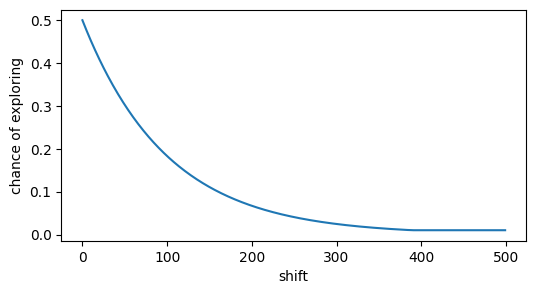

In [4]:
shifts = np.arange(500)
eps = np.maximum(0.01, 0.5 * 0.99 ** shifts)
print("epsilon at shift 0, 100, 300, 499:", np.round(eps[[0, 100, 300, 499]], 3))
plt.figure(figsize=(6, 3))
plt.plot(shifts, eps)
plt.xlabel("shift")
plt.ylabel("chance of exploring")
plt.show()

---
## Slide 13 · UCB term by term
At shift t = 20 with estimates 96 / 112 / 108 and tries 3 / 12 / 5, c = 30:

In [5]:
estimate = np.array([96, 112, 108])
tries = np.array([3, 12, 5])
t, c = 20, 30
bonus = c * np.sqrt(np.log(t) / tries)
score = estimate + bonus
print("ln 20 =", round(np.log(t), 3))
for name, q, b, s in zip(["coarse", "medium", "fine"], estimate, bonus, score):
    print(f"{name:7s} estimate {q}  bonus {b:6.2f}  score {s:7.2f}")
print("UCB chooses:", ["coarse", "medium", "fine"][int(np.argmax(score))])

ln 20 = 2.996
coarse  estimate 96  bonus  29.98  score  125.98
medium  estimate 112  bonus  14.99  score  126.99
fine    estimate 108  bonus  23.22  score  131.22
UCB chooses: fine


---
## Slide 14 · Regret
**Regret** = profit lost compared with always running the best setpoint (medium, $115k). Each method runs 300 times and we average.
This cell makes the chart and the numbers on the slide.

greedy (ε = 0)   total regret   1716 $k   best setpoint  59 % of shifts
ε = 0.3          total regret   1364 $k   best setpoint  73 % of shifts
ε = 0.1          total regret    981 $k   best setpoint  78 % of shifts
decaying ε       total regret    661 $k   best setpoint  84 % of shifts
UCB              total regret    655 $k   best setpoint  84 % of shifts
gradient bandit  total regret    696 $k   best setpoint  83 % of shifts
Thompson         total regret    749 $k   best setpoint  83 % of shifts


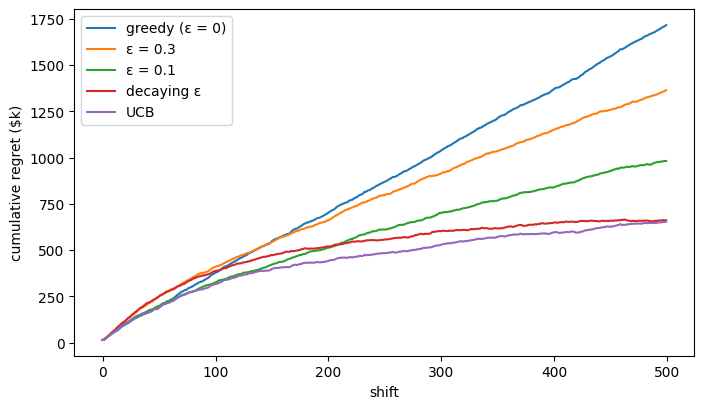

In [6]:
methods = {
    "greedy (ε = 0)":   dict(method="greedy"),
    "ε = 0.3":          dict(method="epsilon", epsilon=0.3),
    "ε = 0.1":          dict(method="epsilon", epsilon=0.1),
    "decaying ε":       dict(method="decaying"),
    "UCB":              dict(method="ucb"),
    "gradient bandit":  dict(method="gradient"),
    "Thompson":         dict(method="thompson"),
}
plt.figure(figsize=(8, 4.5))
for label, settings in methods.items():
    regret = np.zeros(500)
    on_best = []
    for run in range(300):
        profits, tries = run_mill(seed=run, **settings)
        regret += np.cumsum(115 - profits) / 300
        on_best.append(tries[1] / 500)
    print(f"{label:16s} total regret {regret[-1]:6.0f} $k   best setpoint {100 * np.mean(on_best):3.0f} % of shifts")
    if label in ["greedy (ε = 0)", "ε = 0.3", "ε = 0.1", "decaying ε", "UCB"]:
        plt.plot(regret, label=label)
plt.xlabel("shift")
plt.ylabel("cumulative regret ($k)")
plt.legend()
plt.show()

---
## Slide 15 · Regret by hand: ten shifts
True means 100 / 115 / 108; the agent ran coarse 2, medium 5, fine 3 times.

In [7]:
mu = np.array([100, 115, 108])
plays = np.array([2, 5, 3])
gap = mu.max() - mu
print("gaps:", gap)
print("way 1, sum of gaps:", np.sum(plays * gap))
print("way 2, best minus expected:", plays.sum() * mu.max() - np.sum(plays * mu))

gaps: [15  0  7]
way 1, sum of gaps: 51
way 2, best minus expected: 51


---
## Slide 17 · An MDP adds state: the shovel-maintenance problem
**States:** Good, Worn, Broken. **Actions:** Operate or Maintain (a Broken shovel must be Repaired). Rewards in $k per shift.

| State | Action | Reward | Next: Good / Worn / Broken |
|---|---|---|---|
| Good | Operate | +10 | 0.7 / 0.3 / 0 |
| Good | Maintain | +2 | 1.0 / 0 / 0 |
| Worn | Operate | +6 | 0 / 0.6 / 0.4 |
| Worn | Maintain | +2 | 0.9 / 0.1 / 0 |
| Broken | Repair | −20 | 1.0 / 0 / 0 |

In [8]:
# (state, action):  (reward,  {next state: probability})
model = {
    ("Good",   "Operate"):  (10,  {"Good": 0.7, "Worn": 0.3}),
    ("Good",   "Maintain"): (2,   {"Good": 1.0}),
    ("Worn",   "Operate"):  (6,   {"Worn": 0.6, "Broken": 0.4}),
    ("Worn",   "Maintain"): (2,   {"Good": 0.9, "Worn": 0.1}),
    ("Broken", "Repair"):   (-20, {"Good": 1.0}),
}
actions = {"Good": ["Operate", "Maintain"], "Worn": ["Operate", "Maintain"], "Broken": ["Repair"]}
gamma = 0.9        # how much we care about future shifts (0 = only today)

for (state, action), (reward, next_states) in model.items():
    print(f"{state:7s} {action:9s} reward {reward:+4d}   next: {next_states}")

Good    Operate   reward  +10   next: {'Good': 0.7, 'Worn': 0.3}
Good    Maintain  reward   +2   next: {'Good': 1.0}
Worn    Operate   reward   +6   next: {'Worn': 0.6, 'Broken': 0.4}
Worn    Maintain  reward   +2   next: {'Good': 0.9, 'Worn': 0.1}
Broken  Repair    reward  -20   next: {'Good': 1.0}


---
## Slide 18 · The return: adding up future rewards with a discount
One episode: Good/Operate +10, Good/Operate +10, Worn/Operate +6, Broken/Repair −20, Good/Operate +10, with γ = 0.9.

In [9]:
rewards = [10, 10, 6, -20, 10]
G0 = sum(gamma**k * r for k, r in enumerate(rewards))
print("G0 =", round(G0, 2))

G = 0.0                                   # the recursion G_t = r_t+1 + gamma * G_t+1, backwards
for t in reversed(range(len(rewards))):
    G = rewards[t] + gamma * G
    print(f"G{t} = {G:.2f}")
print("constant reward 10 forever:", 10 / (1 - gamma))

G0 = 15.84
G4 = 10.00
G3 = -11.00
G2 = -3.90
G1 = 6.49
G0 = 15.84
constant reward 10 forever: 100.00000000000003


---
## Slide 23 · Where the Bellman equation comes from: numeric check
Using the converged values from the worked example (Good 81.69, Worn 74.92, Broken 53.53):

In [10]:
V = {"Good": 81.69, "Worn": 74.92, "Broken": 53.53}

def value_of(state, action, V):
    reward, next_states = model[(state, action)]
    future = sum(p * V[s] for s, p in next_states.items())
    return reward + gamma * future

print("Worn, Maintain:", round(value_of("Worn", "Maintain", V), 2), " (equals V*(Worn))")
print("Worn, Operate :", round(value_of("Worn", "Operate", V), 2))

Worn, Maintain: 74.91  (equals V*(Worn))
Worn, Operate : 65.73


---
## Slide 24 · Value-based methods: value iteration and Q-learning
**Value iteration** applies the Bellman equation again and again, starting from V = 0.

In [11]:
def value_iteration(iterations=300, show=0):
    V = {"Good": 0, "Worn": 0, "Broken": 0}
    for iteration in range(1, iterations + 1):
        best = {s: max(actions[s], key=lambda a: value_of(s, a, V)) for s in V}   # greedy policy this round
        V = {s: value_of(s, best[s], V) for s in V}                                # Bellman backup
        if iteration <= show:
            print("iteration", iteration, {s: round(v, 2) for s, v in V.items()},
                  " greedy policy (Good / Worn):", best["Good"], "/", best["Worn"])
    return V

**Q-learning** does not use the probability table; it only watches what happens:
1. act (ε-greedy) · 2. target y = r + γ maxₐ′ Q(s′, a′) · 3. TD error δ = y − Q(s, a) · 4. Q(s, a) ← Q(s, a) + α δ

In [12]:
def q_learning(epsilon, shifts=150_000, alpha=0.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = {key: 0.0 for key in model}
    state = "Good"
    for _ in range(shifts):
        options = actions[state]
        if rng.random() < epsilon:
            action = options[rng.integers(len(options))]                  # 1. act: explore
        else:
            action = max(options, key=lambda a: Q[(state, a)])           # 1. act: exploit
        reward, next_states = model[(state, action)]
        next_state = rng.choice(list(next_states), p=list(next_states.values()))   # what happened
        target = reward + gamma * max(Q[(next_state, a)] for a in actions[next_state])  # 2.
        td_error = target - Q[(state, action)]                          # 3.
        Q[(state, action)] += alpha * td_error                           # 4.
        state = next_state
    return Q

for eps in [0.1, 0.0]:
    Q = q_learning(eps)
    print(f"epsilon {eps}: Worn shovel -> Operate {Q[('Worn', 'Operate')]:5.1f}   Maintain {Q[('Worn', 'Maintain')]:5.1f}")

epsilon 0.1: Worn shovel -> Operate  66.7   Maintain  73.5
epsilon 0.0: Worn shovel -> Operate  34.2   Maintain   0.0


---
## Slide 25 · Worked example: two Bellman backups for the shovel
Do iterations 1 and 2 by hand first, then check here.

In [13]:
V = value_iteration(iterations=3, show=3)
V = value_iteration(iterations=300)
print("\nconverged:", {s: round(v, 2) for s, v in V.items()})

print("\nIteration 2, Worn state by hand:")
print("  Operate :", round(6 + 0.9 * (0.6 * 6 + 0.4 * (-20)), 2))
print("  Maintain:", round(2 + 0.9 * (0.9 * 10 + 0.1 * 6), 2))

gamma = 0.1                                   # try it: a short-sighted manager
V01 = value_iteration()
print("\ngamma 0.1 -> Worn shovel:", max(actions["Worn"], key=lambda a: value_of("Worn", a, V01)))
gamma = 0.9                                   # put it back

iteration 1 {'Good': 10.0, 'Worn': 6.0, 'Broken': -20.0}  greedy policy (Good / Worn): Operate / Operate
iteration 2 {'Good': 17.92, 'Worn': 10.64, 'Broken': -11.0}  greedy policy (Good / Worn): Operate / Maintain
iteration 3 {'Good': 24.16, 'Worn': 17.47, 'Broken': -3.87}  greedy policy (Good / Worn): Operate / Maintain

converged: {'Good': 81.69, 'Worn': 74.92, 'Broken': 53.53}

Iteration 2, Worn state by hand:
  Operate : 2.04
  Maintain: 10.64

gamma 0.1 -> Worn shovel: Operate


---
## Slide 26 · Q-learning by hand: four simulated shifts
All Q start at 0, α = 0.1, γ = 0.9. The four shifts on the slide, in order:

In [14]:
Q = {key: 0.0 for key in model}
alpha = 0.1
shifts = [("Worn", "Operate", 6, "Broken"),
          ("Broken", "Repair", -20, "Good"),
          ("Good", "Operate", 10, "Worn"),
          ("Worn", "Operate", 6, "Broken")]
for i, (s, a, r, s2) in enumerate(shifts, start=1):
    target = r + gamma * max(Q[(s2, b)] for b in actions[s2])
    Q[(s, a)] += alpha * (target - Q[(s, a)])
    print(f"shift {i}: {s}, {a}: target {target:6.2f}  ->  Q = {Q[(s, a)]:.2f}")

shift 1: Worn, Operate: target   6.00  ->  Q = 0.60
shift 2: Broken, Repair: target -20.00  ->  Q = -2.00
shift 3: Good, Operate: target  10.54  ->  Q = 1.05
shift 4: Worn, Operate: target   4.20  ->  Q = 0.96


---
## Slide 29 · Policy-based methods: REINFORCE on the shovel problem
The agent learns a **preference** θ for each (state, action) and acts with softmax probabilities. After each episode (30 shifts) it raises the probability
of actions followed by a better-than-usual return: **θ ← θ + α γᵗ (Gₜ − b) ∇ log π(Aₜ | Sₜ, θ)**.

Good -> P(Operate), P(Maintain) = [1. 0.]
Worn -> P(Operate), P(Maintain) = [0.01 0.99]


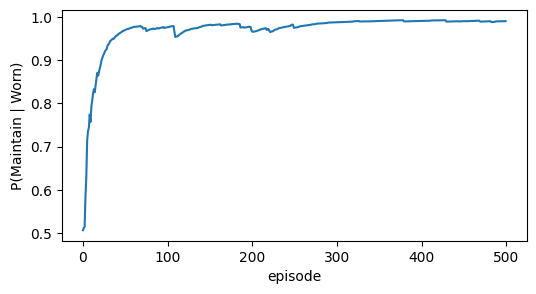

In [15]:
def policy(theta, state):
    """Softmax: turn preferences into probabilities for the actions available in this state."""
    h = np.array([theta[(state, a)] for a in actions[state]])
    e = np.exp(h - h.max())
    return e / e.sum()

def reinforce(episodes=500, shifts=30, alpha=0.01, seed=0):
    rng = np.random.default_rng(seed)
    theta = {key: 0.0 for key in model}            # preferences, all equal at the start
    baseline = {"Good": 0.0, "Worn": 0.0, "Broken": 0.0}
    visits = {"Good": 0, "Worn": 0, "Broken": 0}
    history = []
    for episode in range(episodes):
        state, steps = "Good", []                  # 1. play one episode with the current policy
        for t in range(shifts):
            prob = policy(theta, state)
            i = rng.choice(len(prob), p=prob)
            reward, next_states = model[(state, actions[state][i])]
            steps.append((state, i, reward))
            state = rng.choice(list(next_states), p=list(next_states.values()))
        G = 0.0                                    # 2. walk backwards: return G, then nudge preferences
        for t in reversed(range(len(steps))):
            state, i, reward = steps[t]
            G = reward + gamma * G
            visits[state] += 1
            baseline[state] += (G - baseline[state]) / visits[state]
            prob = policy(theta, state)
            for j, a in enumerate(actions[state]):
                chosen = 1 if j == i else 0
                theta[(state, a)] += alpha * gamma**t * (G - baseline[state]) * (chosen - prob[j])
        history.append(policy(theta, "Worn")[1])   # chance of Maintain when Worn
    return theta, history

theta, history = reinforce()
for s in ["Good", "Worn"]:
    print(s, "-> P(Operate), P(Maintain) =", np.round(policy(theta, s), 2))
plt.figure(figsize=(6, 3))
plt.plot(history)
plt.xlabel("episode")
plt.ylabel("P(Maintain | Worn)")
plt.show()

---
## Slide 30 · Worked example: one policy-gradient step on the grind setpoints
Same problem as the bandit slides. Preferences start at 0 (π = ⅓ each). This shift we run **Medium** and earn **$120k**; the average so far is **$105k**; α = 0.02.
**H(a) ← H(a) + α (R − R_avg)(1{a = Aₜ} − π(a))**

In [16]:
def one_step(reward, average=105, alpha=0.02, chosen=1):
    H = np.zeros(3)
    prob = np.exp(H) / np.exp(H).sum()
    for a in range(3):
        H[a] += alpha * (reward - average) * ((1 if a == chosen else 0) - prob[a])
    new_prob = np.exp(H) / np.exp(H).sum()
    print(f"R = {reward}: preferences {np.round(H, 3)}  ->  probabilities {np.round(new_prob, 3)}")

one_step(120)     # better than average: Medium becomes more likely
one_step(95)      # worse than average: Medium becomes less likely

on_best, regret = [], []
for run in range(300):
    profits, tries = run_mill("gradient", seed=run)
    on_best.append(tries[1] / 500)
    regret.append(np.sum(115 - profits))
print(f"\n500 shifts x 300 runs: best setpoint {100 * np.mean(on_best):.0f} % of shifts, total regret {np.mean(regret):.0f} $k")

R = 120: preferences [-0.1  0.2 -0.1]  ->  probabilities [0.299 0.403 0.299]
R = 95: preferences [ 0.067 -0.133  0.067]  ->  probabilities [0.355 0.29  0.355]

500 shifts x 300 runs: best setpoint 83 % of shifts, total regret 696 $k


---
## Slide 34 · Bayes' rule by hand: is this drillhole in the ore zone?
Prior P(ore) = 0.30; the lab reads "high" for 80 % of ore samples and 10 % of waste samples. Two high assays in a row:

In [17]:
p_ore = 0.30
for assay in [1, 2]:
    p_high = 0.80 * p_ore + 0.10 * (1 - p_ore)      # chance of a high assay overall
    p_ore = 0.80 * p_ore / p_high                    # Bayes' rule
    print(f"after high assay {assay}: P(high) = {p_high:.3f}, P(ore | data) = {p_ore:.2f}")

after high assay 1: P(high) = 0.310, P(ore | data) = 0.77
after high assay 2: P(high) = 0.642, P(ore | data) = 0.96


---
## Slide 35 · The Gaussian building block
Profit at 1 600 and 1 700 t/h, each N(50, 5²), correlation 0.8. We test 1 600 t/h and see 58:

In [18]:
mu, sd, rho, y1 = 50, 5, 0.8, 58
print("95 % range before testing:", round(mu - 1.96 * sd, 1), "to", round(mu + 1.96 * sd, 1))
print("mean at 1 700 after seeing 58:", mu + rho * (sd / sd) * (y1 - mu))
print("sd at 1 700 after seeing 58:  ", round(sd * np.sqrt(1 - rho**2), 2))

95 % range before testing: 40.2 to 59.8
mean at 1 700 after seeing 58: 56.4
sd at 1 700 after seeing 58:   3.0


---
## Slide 36 · From Bayes' rule to a Gaussian process
Running example for Bayesian optimization: **SAG mill throughput**. More tonnes per hour means more feed but a coarser grind and lower recovery,
so profit has a best setpoint. Each trial is expensive.

In [19]:
def plant_trial(throughput, rng):
    """Profit in $k/h for one trial. The optimizer only sees the number it returns."""
    x = (throughput - 800) / 1200
    recovery = 0.93 - 0.35 * x**2 - 0.04 * np.sin(6 * x)
    profit = throughput * (0.006 * 1000 * recovery * 9 - 6) / 1000
    return profit + rng.normal(0, 0.4)                     # measurement noise

def true_profit_at(t):                                     # the hidden curve, without noise
    x = (t - 800) / 1200
    return t * (0.006 * 1000 * (0.93 - 0.35 * x**2 - 0.04 * np.sin(6 * x)) * 9 - 6) / 1000

setpoints = np.linspace(800, 2000, 400)                    # every setpoint we could choose

The posterior formulas on the slide, coded directly with numpy:
**μ(x) = k(x)ᵀ (K + σₙ² I)⁻¹ y** and **σ²(x) = k(x, x) − k(x)ᵀ (K + σₙ² I)⁻¹ k(x)**, with **k(x, x′) = s² exp(−(x − x′)² / 2ℓ²)**.

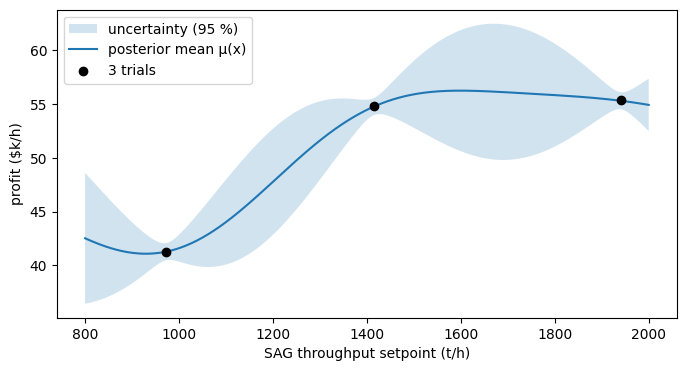

In [20]:
def kernel(a, b, s=5.0, length=250.0):
    return s**2 * np.exp(-(a[:, None] - b[None, :]) ** 2 / (2 * length**2))

rng = np.random.default_rng(1)
tested = rng.uniform(800, 2000, 3)                 # 3 trials
results = np.array([plant_trial(t, rng) for t in tested])

mean_y = results.mean()                            # work around the average result
K = kernel(tested, tested) + 0.4**2 * np.eye(3)    # similarity between tested points (+ noise)
k = kernel(setpoints, tested)                      # similarity of every setpoint to the tested ones
mu = mean_y + k @ np.linalg.solve(K, results - mean_y)
var = 5.0**2 - np.sum(k * np.linalg.solve(K, k.T).T, axis=1)
sd = np.sqrt(np.maximum(var, 0))

plt.figure(figsize=(8, 4))
plt.fill_between(setpoints, mu - 2 * sd, mu + 2 * sd, alpha=0.2, label="uncertainty (95 %)")
plt.plot(setpoints, mu, label="posterior mean μ(x)")
plt.scatter(tested, results, color="black", zorder=3, label="3 trials")
plt.xlabel("SAG throughput setpoint (t/h)")
plt.ylabel("profit ($k/h)")
plt.legend()
plt.show()

---
## Slide 37 · The Bayesian optimization loop
1. run the simulation · 2. fit the model · 3. compute the acquisition function · 4. choose the next setpoint · 5. run again.
scikit-learn fits the Gaussian process (and learns the length scale from the data). The three acquisition functions:

In [21]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel

def expected_improvement(mean, sd, best):
    z = (mean - best) / sd
    return (mean - best) * norm.cdf(z) + sd * norm.pdf(z)

def upper_confidence_bound(mean, sd, kappa=2.0):
    return mean + kappa * sd

def probability_of_improvement(mean, sd, best):
    return norm.cdf((mean - best) / sd)

rng = np.random.default_rng(1)
tested = list(rng.uniform(800, 2000, 3))                   # step 1: 3 random first trials
results = [plant_trial(t, rng) for t in tested]
gp = GaussianProcessRegressor(
    ConstantKernel() * Matern(length_scale=300, length_scale_bounds=(150, 3000), nu=2.5)
    + WhiteKernel(0.01, noise_level_bounds=(1e-4, 1e-1)), normalize_y=True)

snapshots = {}
for step in range(1, 9):
    gp.fit(np.array(tested).reshape(-1, 1), results)       # step 2: fit the model
    mean, sd = gp.predict(setpoints.reshape(-1, 1), return_std=True)
    sd = np.maximum(sd, 1e-9)
    acquisition = expected_improvement(mean, sd, max(results))   # step 3 (try the other two!)
    next_setpoint = setpoints[np.argmax(acquisition)]       # step 4
    if len(tested) in (3, 6):
        snapshots[len(tested)] = (list(tested), list(results), mean, sd, acquisition, next_setpoint)
    tested.append(next_setpoint)
    results.append(plant_trial(next_setpoint, rng))         # step 5
    print(f"step {step}: test {next_setpoint:5.0f} t/h -> profit {results[-1]:.2f} $k/h")

gp.fit(np.array(tested).reshape(-1, 1), results)
mean, sd = gp.predict(setpoints.reshape(-1, 1), return_std=True)
print("\nBest guess after", len(tested), "trials:", round(setpoints[np.argmax(mean)]), "t/h")
print("True best setpoint:", round(setpoints[np.argmax(true_profit_at(setpoints))]), "t/h")

step 1: test  1805 t/h -> profit 59.39 $k/h
step 2: test  1669 t/h -> profit 60.86 $k/h
step 3: test  1693 t/h -> profit 60.84 $k/h
step 4: test  1678 t/h -> profit 60.78 $k/h
step 5: test  1681 t/h -> profit 60.68 $k/h
step 6: test  1684 t/h -> profit 60.90 $k/h
step 7: test  1687 t/h -> profit 60.39 $k/h
step 8: test  1675 t/h -> profit 60.59 $k/h

Best guess after 11 trials: 1684 t/h
True best setpoint: 1696 t/h


---
## Slide 38 · Acquisition functions: the figure
The model and Expected Improvement after 3 and after 6 trials (orange line = next trial).

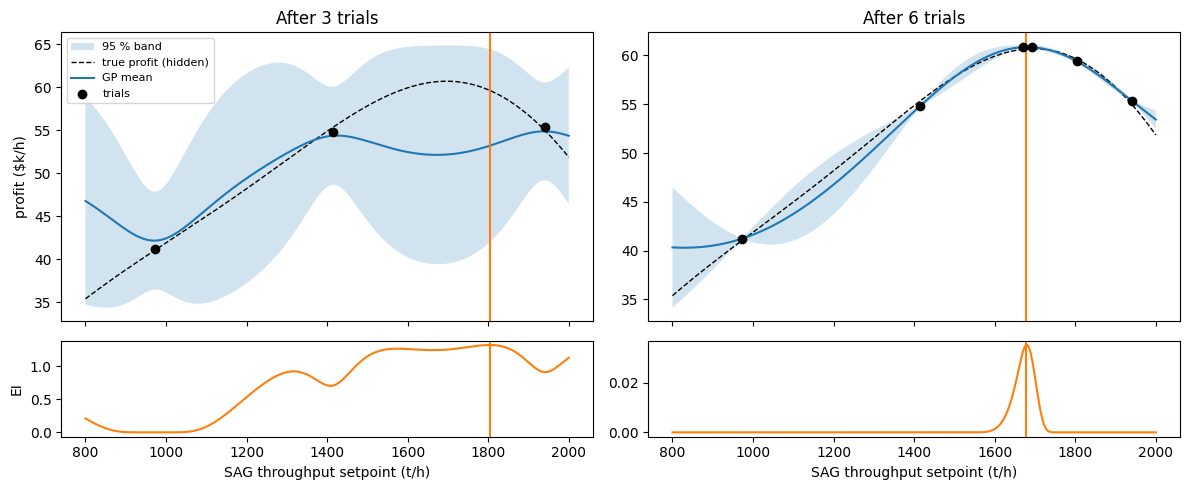

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for col, n in enumerate([3, 6]):
    t, r, m, s, acq, nxt = snapshots[n]
    ax[0, col].fill_between(setpoints, m - 2 * s, m + 2 * s, alpha=0.2, label="95 % band")
    ax[0, col].plot(setpoints, true_profit_at(setpoints), "k--", lw=1, label="true profit (hidden)")
    ax[0, col].plot(setpoints, m, label="GP mean")
    ax[0, col].scatter(t, r, color="black", zorder=3, label="trials")
    ax[0, col].axvline(nxt, color="C1")
    ax[0, col].set_title(f"After {n} trials")
    ax[1, col].plot(setpoints, acq, color="C1")
    ax[1, col].axvline(nxt, color="C1")
    ax[1, col].set_xlabel("SAG throughput setpoint (t/h)")
ax[0, 0].set_ylabel("profit ($k/h)")
ax[1, 0].set_ylabel("EI")
ax[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Slide 39 · Expected Improvement by hand
Best so far f⁺ = 60.86. Candidate A: μ = 60.5, σ = 0.3 (next to the best trial). Candidate B: μ = 58.0, σ = 3.0 (far from any trial).

In [23]:
best = 60.86
for name, mu, sd in [("A", 60.5, 0.3), ("B", 58.0, 3.0)]:
    z = (mu - best) / sd
    ei = (mu - best) * norm.cdf(z) + sd * norm.pdf(z)
    print(f"{name}: z = {z:5.2f}  Phi = {norm.cdf(z):.3f}  phi = {norm.pdf(z):.3f}  EI = {ei:.3f}")

A: z = -1.20  Phi = 0.115  phi = 0.194  EI = 0.017
B: z = -0.95  Phi = 0.170  phi = 0.253  EI = 0.273


**Questions**
* Replace `expected_improvement(...)` in the loop with `upper_confidence_bound(mean, sd)`. How do the trials change?
* In the Gaussian-process cell, change `length=250` to `100` or `600`. What happens between trials?